In [1]:
import pandas as pd
test = pd.read_csv("test.csv")
test.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-07-19 11:00:00,3,0,1,1,33.62,40.150,59,0.0000,29,98,127
1,2012-01-16 06:00:00,1,1,0,1,4.10,6.820,54,6.0032,0,13,13
2,2011-12-11 18:00:00,4,0,0,1,9.84,11.365,48,12.9980,12,151,163
3,2012-08-15 10:00:00,3,0,1,2,29.52,34.090,62,12.9980,70,163,233
4,2012-06-15 23:00:00,2,0,1,1,25.42,31.060,53,16.9979,46,176,222


In [2]:
train = pd.read_csv("train.csv")
train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-07-06 05:00:00,3,0,1,1,27.88,31.820,83,6.0032,5,30,35
1,2012-08-04 16:00:00,3,0,0,1,36.90,40.910,39,19.9995,197,253,450
2,2012-07-11 15:00:00,3,0,1,1,32.80,35.605,41,16.9979,56,220,276
3,2011-04-10 04:00:00,2,0,0,2,14.76,18.180,93,7.0015,3,2,5
4,2011-11-19 10:00:00,4,0,0,1,13.12,15.150,45,16.9979,35,165,200


In [3]:
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 8708 entries, 0 to 8707
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    8708 non-null   str    
 1   season      8708 non-null   int64  
 2   holiday     8708 non-null   int64  
 3   workingday  8708 non-null   int64  
 4   weather     8708 non-null   int64  
 5   temp        8708 non-null   float64
 6   atemp       8708 non-null   float64
 7   humidity    8708 non-null   int64  
 8   windspeed   8708 non-null   float64
 9   casual      8708 non-null   int64  
 10  registered  8708 non-null   int64  
 11  count       8708 non-null   int64  
dtypes: float64(3), int64(8), str(1)
memory usage: 816.5 KB


In [4]:
# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,8708,8708.000000,8708.000000,8708.000000,8708.000000,8708.000000,8708.000000,8708.000000,8708.000000,8708.000000,8708.000000,8708.000000
unique,8708,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2011-07-06 05:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2.507694,0.029169,0.680983,1.416743,20.269104,23.694257,61.811438,12.795542,35.995866,155.588884,191.584750
std,NaN,1.115295,0.168289,0.466122,0.634073,7.788428,8.460347,19.288803,8.200255,49.858679,151.132186,181.010715
min,NaN,1.000000,0.000000,0.000000,1.000000,0.820000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,NaN,2.000000,0.000000,0.000000,1.000000,13.940000,16.665000,47.000000,7.001500,4.000000,36.000000,43.000000
50%,NaN,3.000000,0.000000,1.000000,1.000000,20.500000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,NaN,4.000000,0.000000,1.000000,2.000000,26.240000,31.060000,77.000000,16.997900,49.000000,223.000000,285.000000


In [5]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [6]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [7]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [8]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object']).columns
for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

C:\Users\JIHAN HADIYANTI\AppData\Local\Temp\ipykernel_8684\2814590153.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kategorical_features = train[less].select_dtypes(include=['object']).columns


In [9]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [10]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

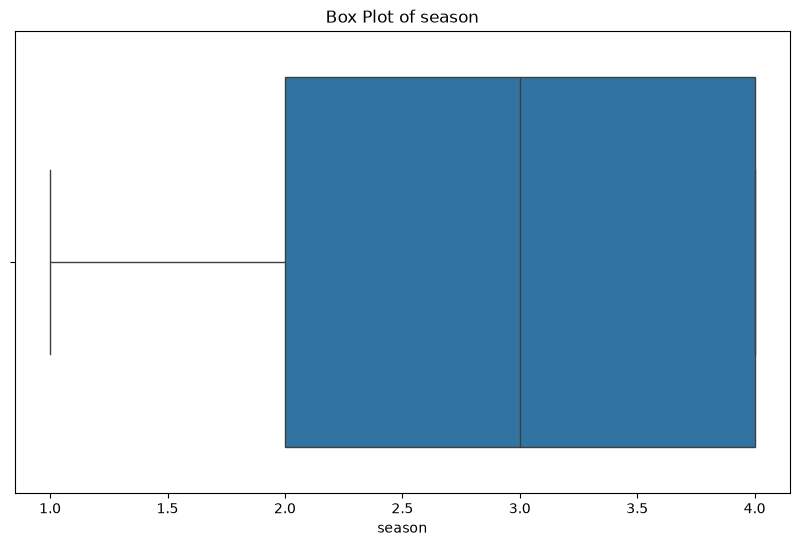

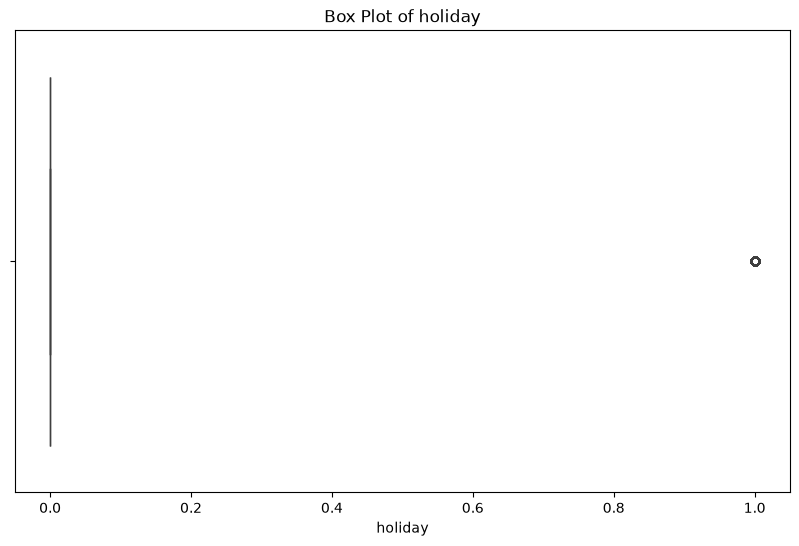

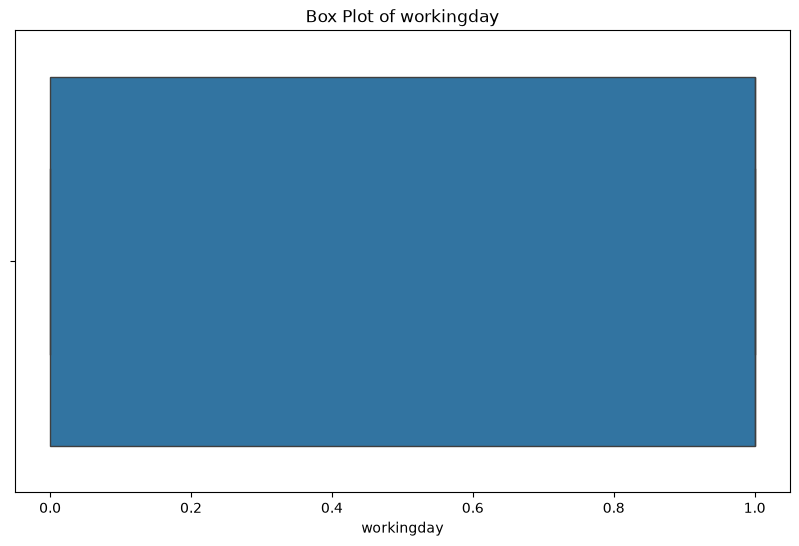

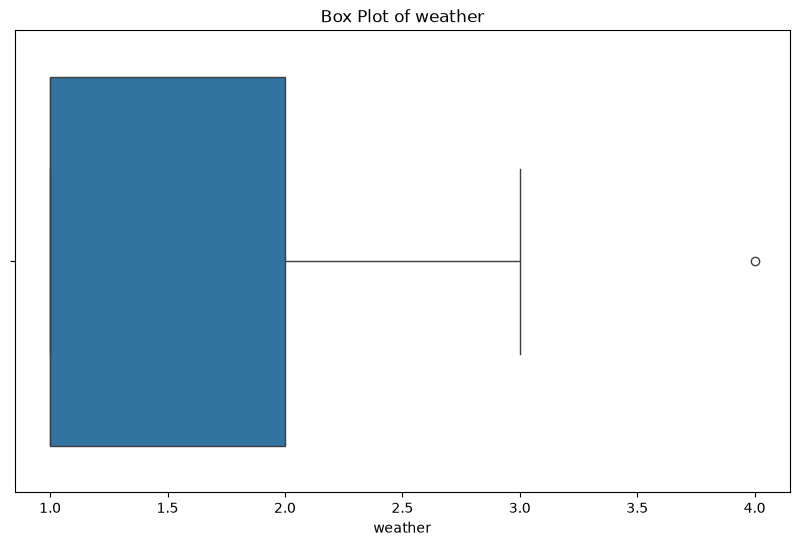

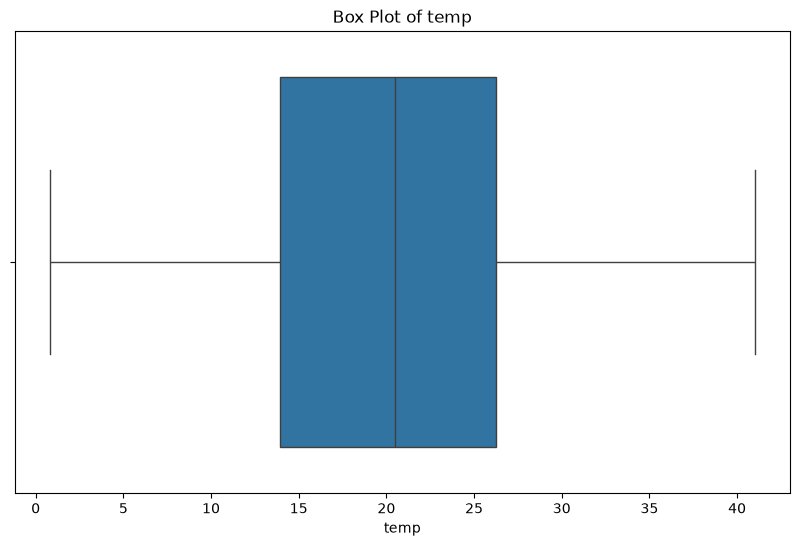

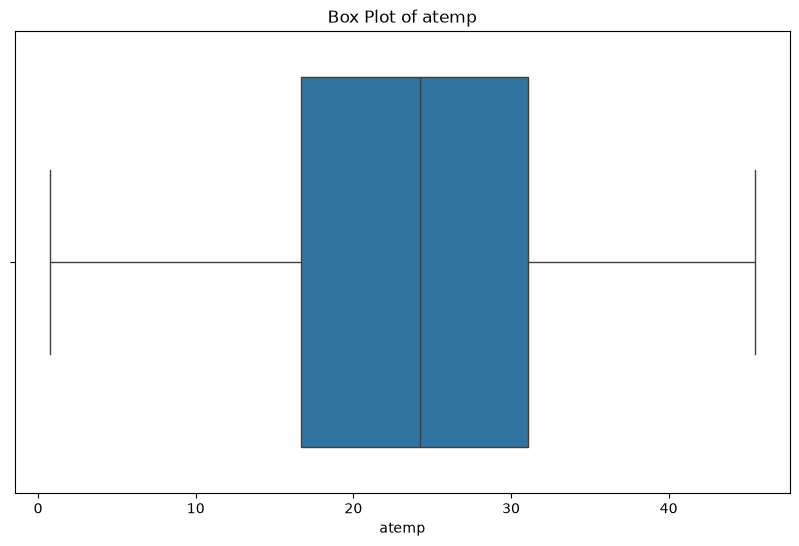

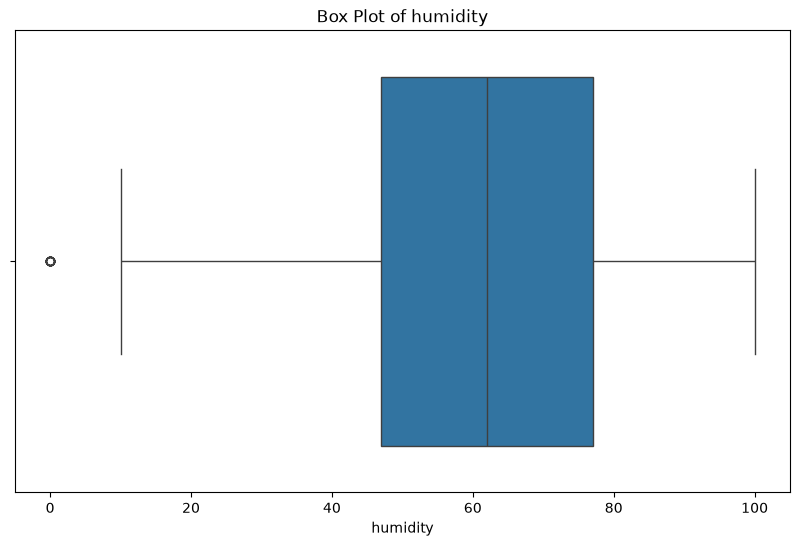

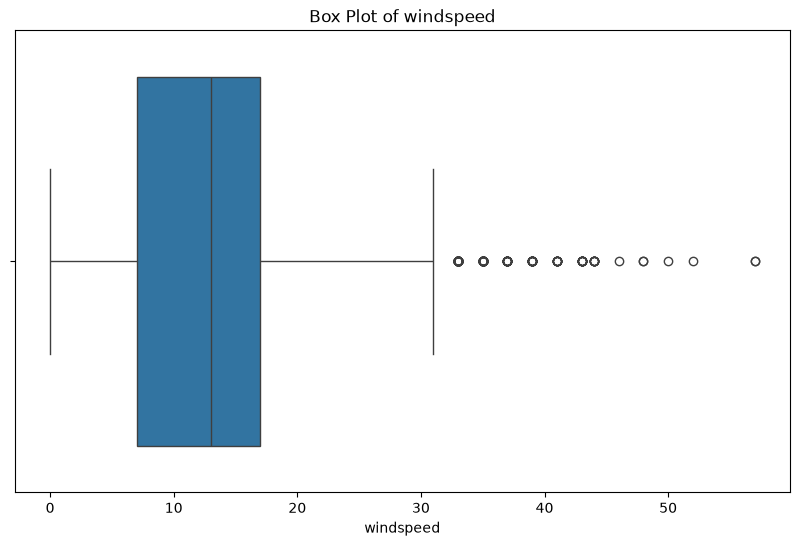

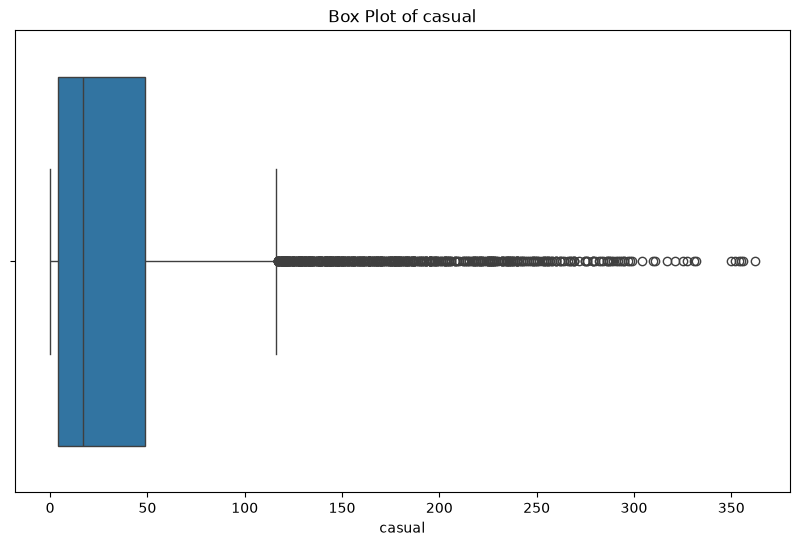

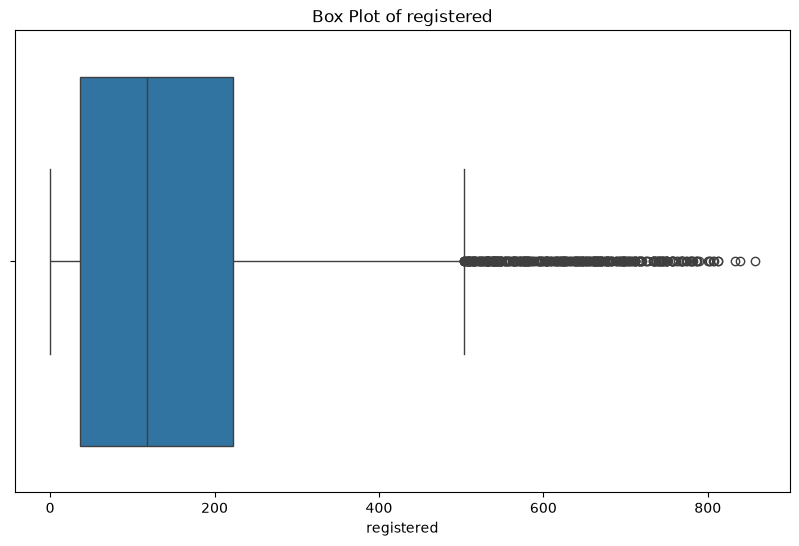

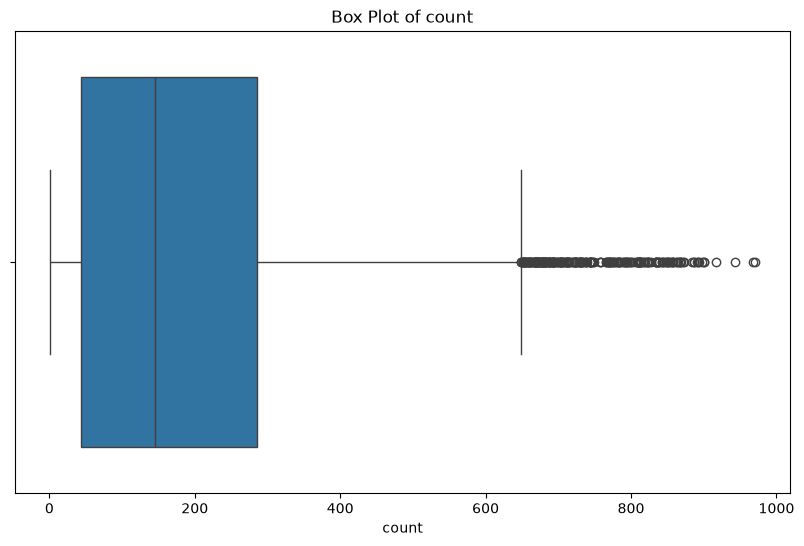

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [12]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [13]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

C:\Users\JIHAN HADIYANTI\AppData\Local\Temp\ipykernel_8684\1961368722.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns


In [14]:
# Mengganti outlier dengan nilai batas terdekat untuk semua kolom numerik
for col in numeric_features:
    lower_bound = Q1[col] - 1.5 * IQR[col]
    upper_bound = Q3[col] + 1.5 * IQR[col]
    
    df[col] = df[col].apply(
        lambda x: lower_bound if x < lower_bound else (upper_bound if x > upper_bound else x)
    )

In [15]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

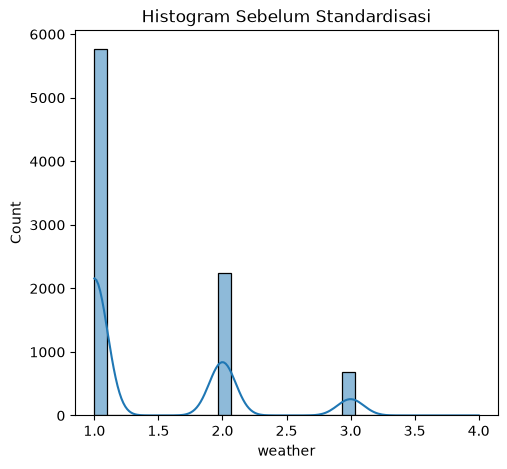

In [16]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

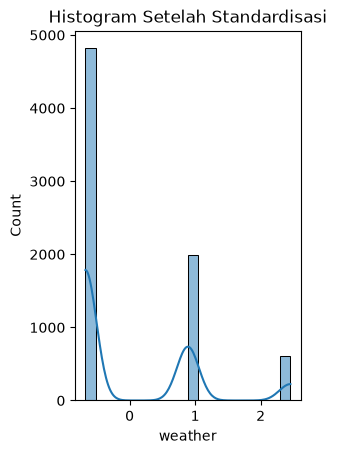

In [17]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [18]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [season, holiday, workingday, weather, temp, atemp, humidity, windspeed, casual, registered, count, datetime]
Index: []


In [19]:
# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
        season  holiday  workingday   weather      temp     atemp  humidity  \
0     0.442076      0.0    0.602148 -0.674965  1.070044  1.049166  1.031589   
2     0.442076      0.0    0.602148 -0.674965  1.711697  1.503808 -1.207885   
3    -0.441957      0.0   -1.660720  0.889323 -0.641033 -0.589227  1.564797   
4     1.326109      0.0   -1.660720 -0.674965 -0.854917 -0.953181 -0.994602   
5    -1.325990      0.0    0.602148 -0.674965 -0.747975 -0.771204 -2.061018   
...        ...      ...         ...       ...       ...       ...       ...   
8702 -1.325990      0.0    0.602148  0.889323 -1.068802 -1.043869  1.564797   
8703 -1.325990      0.0   -1.660720 -0.674965 -1.710455 -1.771776 -0.887960   
8704  1.326109      0.0   -1.660720 -0.674965 -1.068802 -1.225846 -0.141469   
8705  1.326109      0.0   -1.660720 -0.674965 -1.068802 -1.135157 -0.834639   
8707 -0.441957      0.0    0.602148  0.889323  0.321448  0.321258  1.298193   

      windspe

In [20]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

C:\Users\JIHAN HADIYANTI\AppData\Local\Temp\ipykernel_8684\2319133481.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = df.select_dtypes(include=['object']).columns


,datetime
0,2011-07-06 05:00:00
2,2012-07-11 15:00:00
3,2011-04-10 04:00:00
4,2011-11-19 10:00:00
5,2012-02-13 19:00:00
...,...
8702,2012-02-17 07:00:00
8703,2012-01-14 02:00:00
8704,2011-12-10 09:00:00
8705,2011-12-18 16:00:00


In [21]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,...,datetime_2012-12-19 07:00:00,datetime_2012-12-19 09:00:00,datetime_2012-12-19 10:00:00,datetime_2012-12-19 11:00:00,datetime_2012-12-19 12:00:00,datetime_2012-12-19 15:00:00,datetime_2012-12-19 16:00:00,datetime_2012-12-19 19:00:00,datetime_2012-12-19 20:00:00,datetime_2012-12-19 21:00:00
0,0.442076,0.0,0.602148,-0.674965,1.070044,1.049166,1.031589,-0.818548,-0.705584,-0.845521,...,False,False,False,False,False,False,False,False,False,False
2,0.442076,0.0,0.602148,-0.674965,1.711697,1.503808,-1.207885,0.660805,1.189079,0.810926,...,False,False,False,False,False,False,False,False,False,False
3,-0.441957,0.0,-1.660720,0.889323,-0.641033,-0.589227,1.564797,-0.684225,-0.779884,-1.089629,...,False,False,False,False,False,False,False,False,False,False
4,1.326109,0.0,-1.660720,-0.674965,-0.854917,-0.953181,-0.994602,0.660805,0.408924,0.331428,...,False,False,False,False,False,False,False,False,False,False
5,-1.325990,0.0,0.602148,-0.674965,-0.747975,-0.771204,-2.061018,-0.415580,-0.631283,1.124779,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8702,-1.325990,0.0,0.602148,0.889323,-1.068802,-1.043869,1.564797,-0.684225,-0.742734,0.828362,...,False,False,False,False,False,False,False,False,False,False
8703,-1.325990,0.0,-1.660720,-0.674965,-1.710455,-1.771776,-0.887960,-0.146033,-0.668434,-0.828085,...,False,False,False,False,False,False,False,False,False,False
8704,1.326109,0.0,-1.660720,-0.674965,-1.068802,-1.225846,-0.141469,0.930351,-0.334081,0.061166,...,False,False,False,False,False,False,False,False,False,False
8705,1.326109,0.0,-1.660720,-0.674965,-1.068802,-1.135157,-0.834639,0.660805,0.111722,0.697590,...,False,False,False,False,False,False,False,False,False,False


In [22]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,datetime
0,0.442076,0.0,0.602148,-0.674965,1.070044,1.049166,1.031589,-0.818548,-0.705584,-0.845521,-0.878774,2015
2,0.442076,0.0,0.602148,-0.674965,1.711697,1.503808,-1.207885,0.660805,1.189079,0.810926,0.947321,5821
3,-0.441957,0.0,-1.660720,0.889323,-0.641033,-0.589227,1.564797,-0.684225,-0.779884,-1.089629,-1.106089,1122
4,1.326109,0.0,-1.660720,-0.674965,-0.854917,-0.953181,-0.994602,0.660805,0.408924,0.331428,0.371457,3526
5,-1.325990,0.0,0.602148,-0.674965,-0.747975,-0.771204,-2.061018,-0.415580,-0.631283,1.124779,0.848818,4413
...,...,...,...,...,...,...,...,...,...,...,...,...
8702,-1.325990,0.0,0.602148,0.889323,-1.068802,-1.043869,1.564797,-0.684225,-0.742734,0.828362,0.568463,4477
8703,-1.325990,0.0,-1.660720,-0.674965,-1.710455,-1.771776,-0.887960,-0.146033,-0.668434,-0.828085,-0.856043,4101
8704,1.326109,0.0,-1.660720,-0.674965,-1.068802,-1.225846,-0.141469,0.930351,-0.334081,0.061166,-0.014978,3715
8705,1.326109,0.0,-1.660720,-0.674965,-1.068802,-1.135157,-0.834639,0.660805,0.111722,0.697590,0.629080,3865


In [23]:
df_lencoder.head()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,datetime
0,0.442076,0.0,0.602148,-0.674965,1.070044,1.049166,1.031589,-0.818548,-0.705584,-0.845521,-0.878774,2015
2,0.442076,0.0,0.602148,-0.674965,1.711697,1.503808,-1.207885,0.660805,1.189079,0.810926,0.947321,5821
3,-0.441957,0.0,-1.660720,0.889323,-0.641033,-0.589227,1.564797,-0.684225,-0.779884,-1.089629,-1.106089,1122
4,1.326109,0.0,-1.660720,-0.674965,-0.854917,-0.953181,-0.994602,0.660805,0.408924,0.331428,0.371457,3526
5,-1.325990,0.0,0.602148,-0.674965,-0.747975,-0.771204,-2.061018,-0.415580,-0.631283,1.124779,0.848818,4413


In [24]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

# Menampilkan kolom dengan missing values saja
missing_data[missing_data['Missing Values'] > 0]

,Missing Values,Percentage


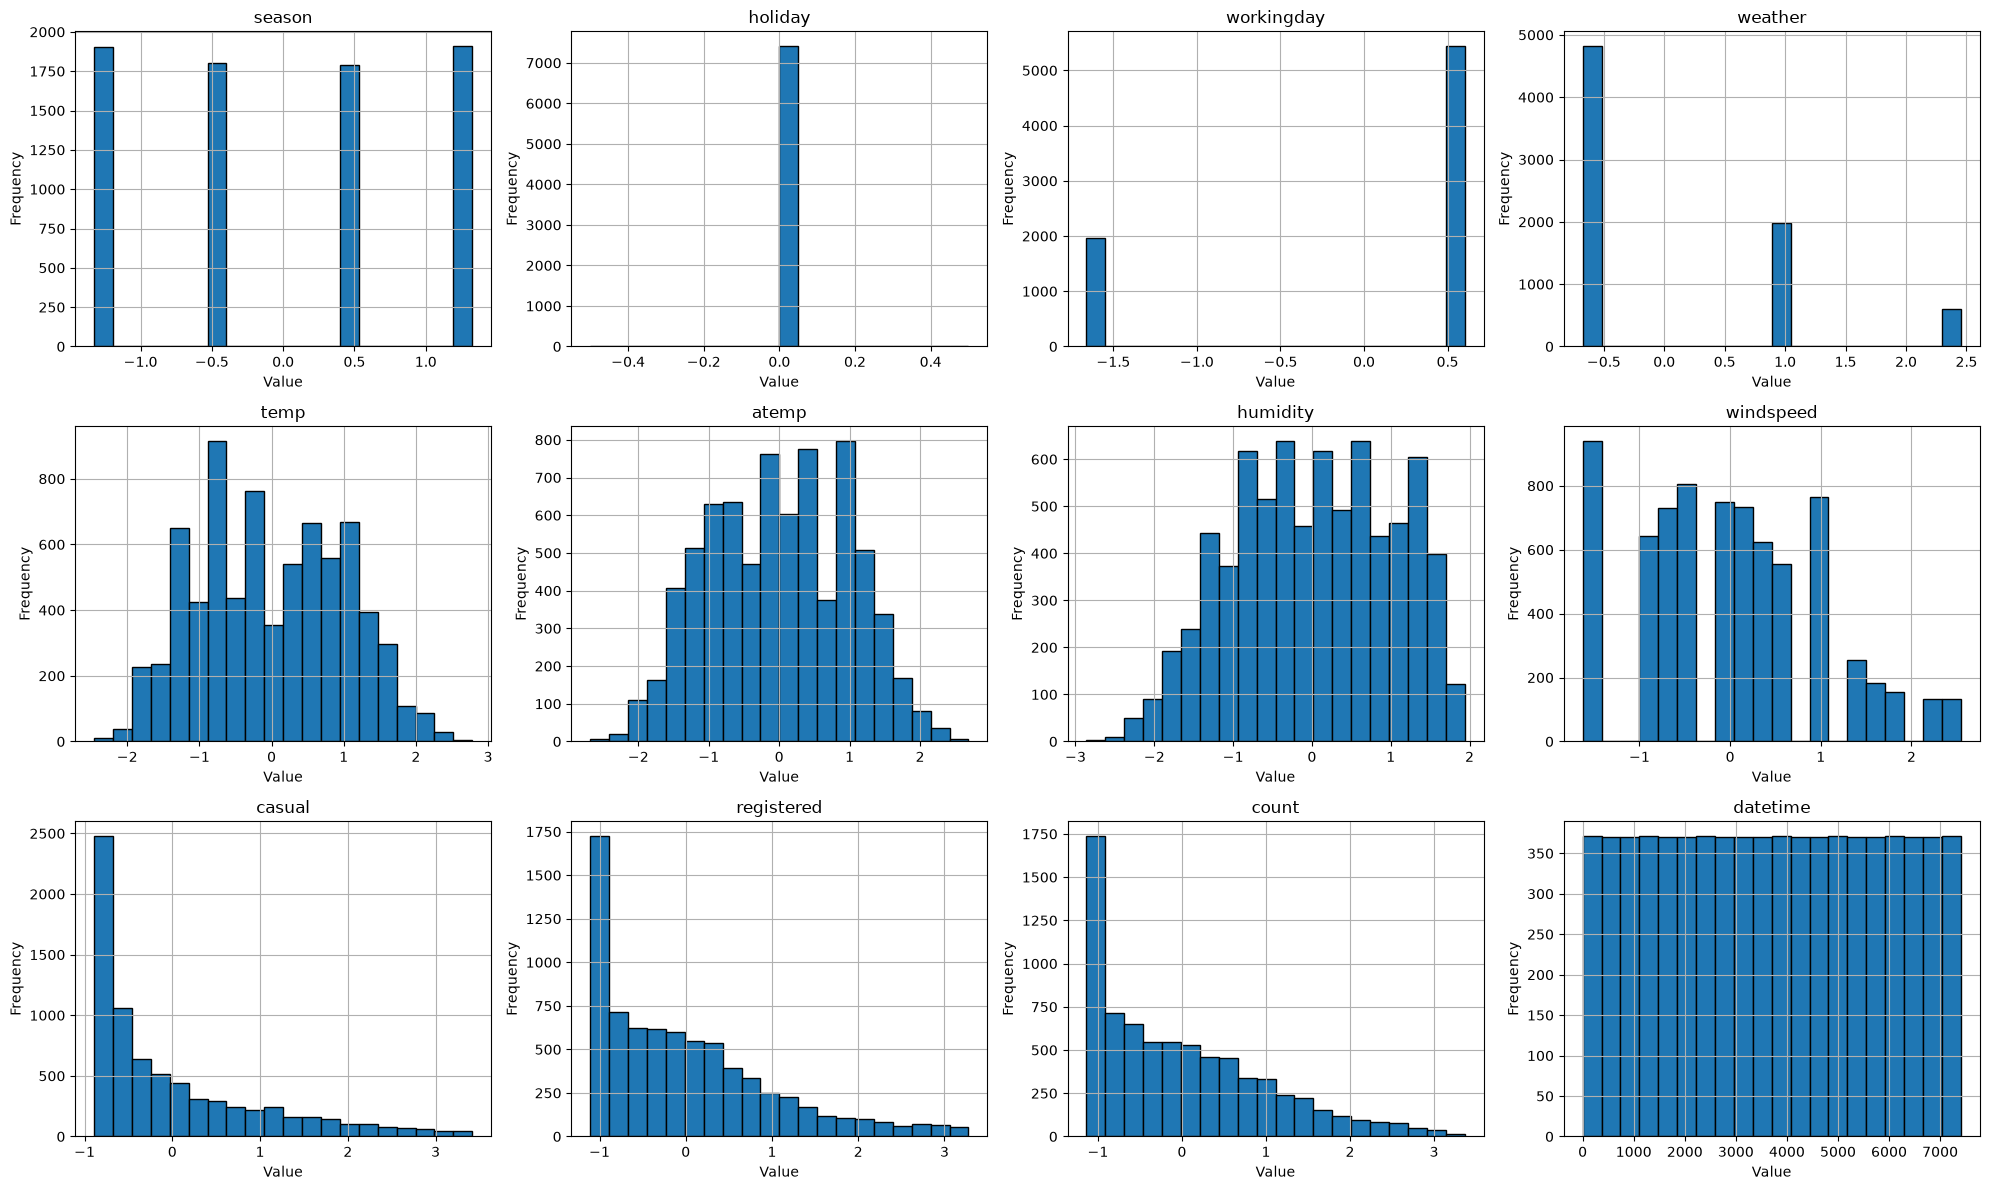

In [25]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4  # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols)  # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

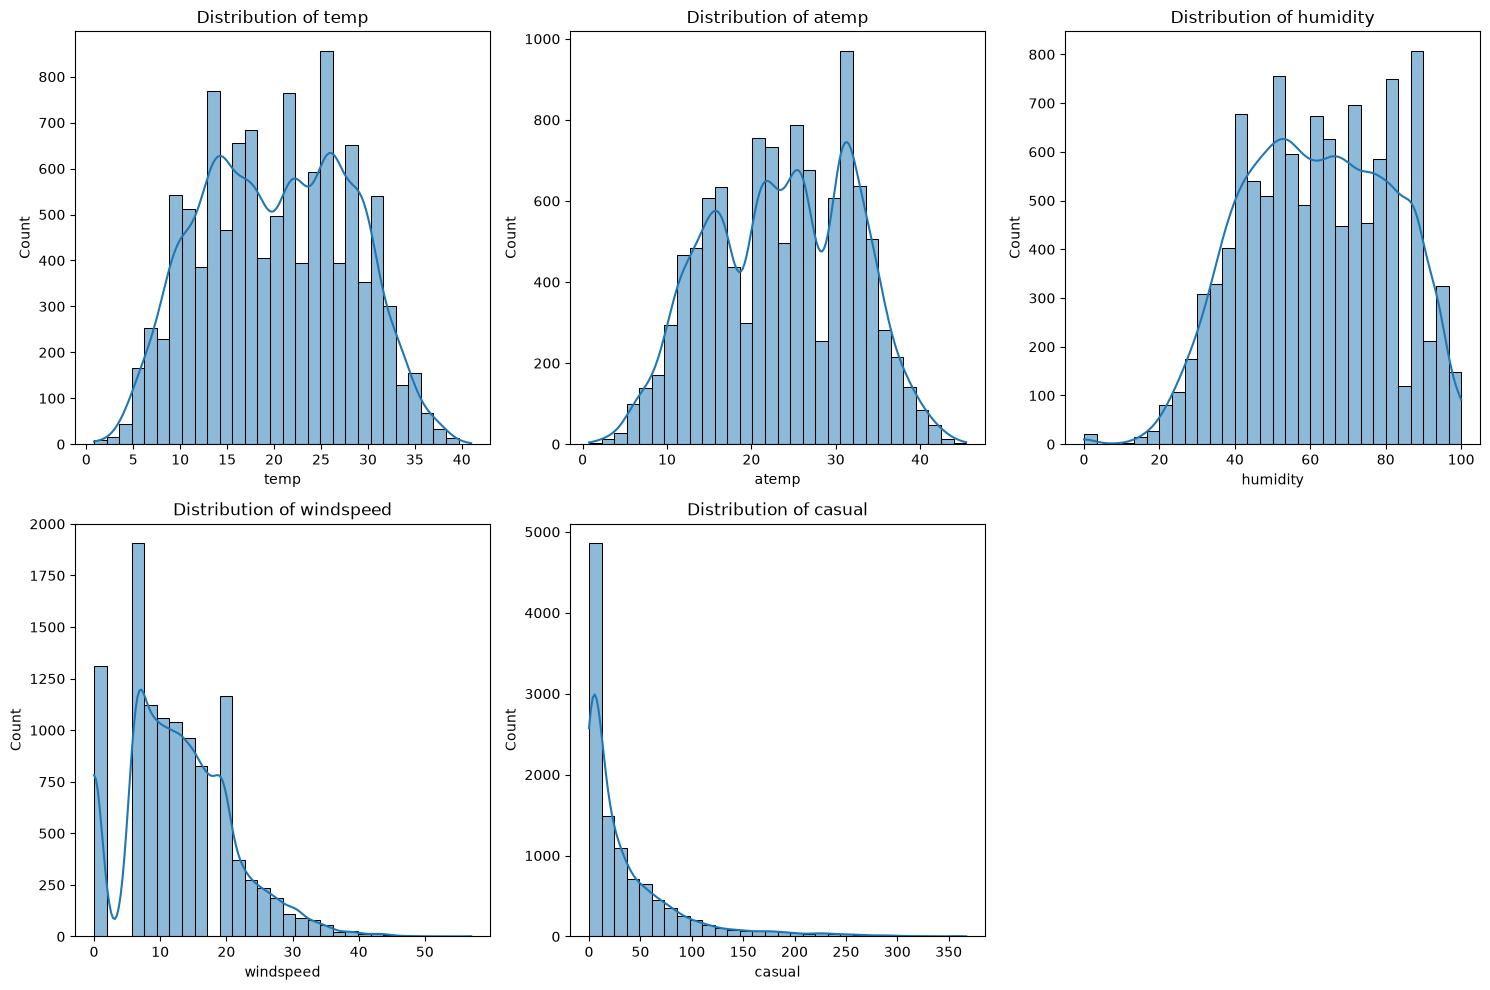

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset baru
df = pd.read_csv('bike_sharing.csv')

# Kolom yang ingin divisualisasikan dari bike_sharing.csv
columns_to_plot = ['temp', 'atemp', 'humidity', 'windspeed', 'casual']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

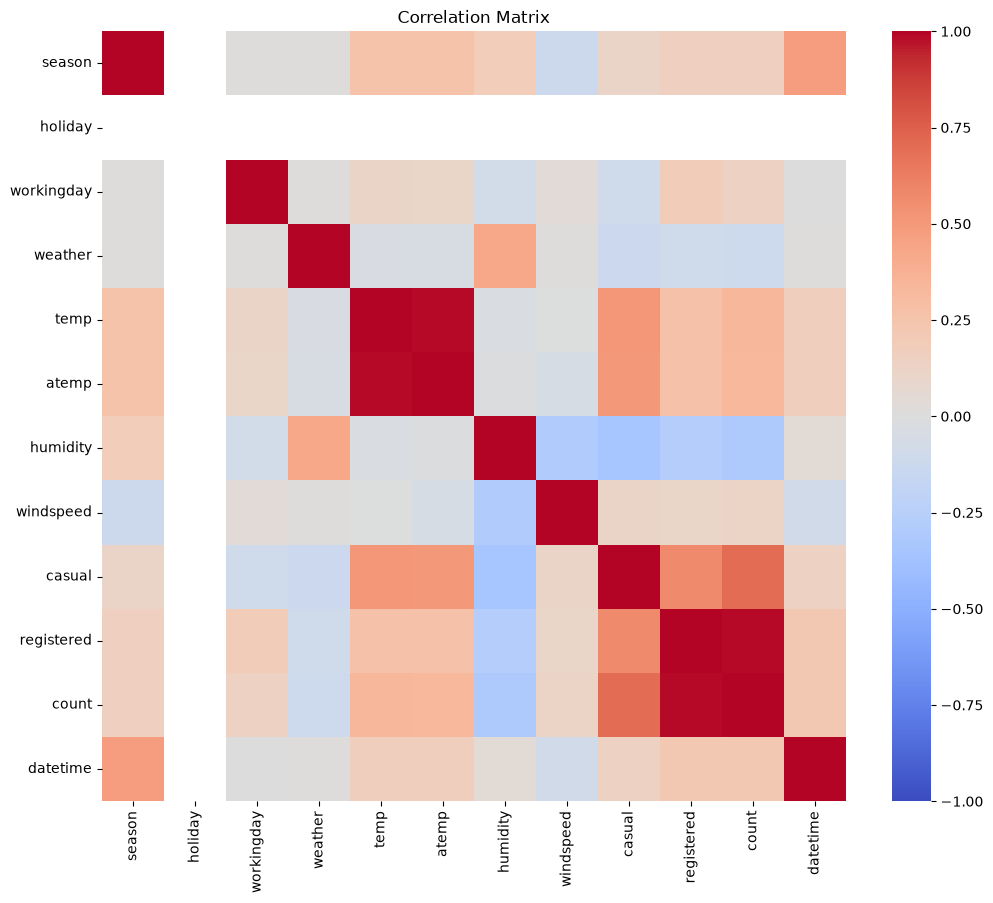

In [27]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

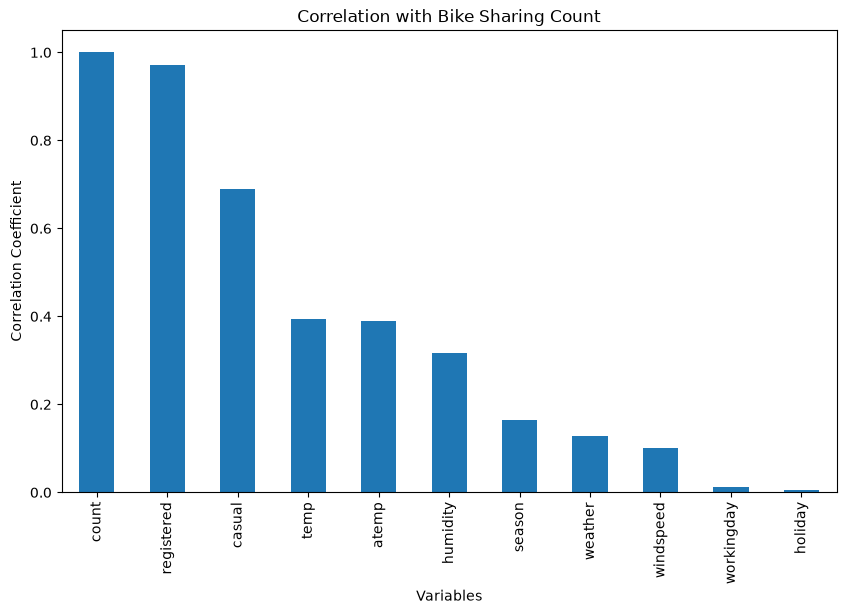

In [28]:
# Menghitung korelasi antara variabel target ('count') dan semua variabel lainnya
target_corr = df.corr(numeric_only=True)['count']

# (Opsional) Mengurutkan hasil korelasi berdasarkan nilai absolutnya
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title('Correlation with Bike Sharing Count')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

In [29]:
import sklearn

In [30]:
# Memisahkan fitur (X) dan target (y) untuk dataset bike_sharing
# Kita drop kolom 'datetime' dan kolom target 'count' untuk fitur (X)
X = df.drop(columns=['datetime', 'count']) 
y = df['count']

In [31]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [32]:
# menghitung panjang/jumlah data 
print("Jumlah data: ", len(X))

# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ", len(x_train))

# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ", len(x_test))

Jumlah data:  10886
Jumlah data latih:  8708
Jumlah data test:  2178


In [33]:
import pandas as pd

# Memuat dataset baru bike_sharing.csv
df = pd.read_csv('bike_sharing.csv')

# Menampilkan beberapa baris pertama untuk memastikan data sudah masuk
print(df.head())

              datetime  season  holiday  workingday  weather  temp   atemp  \
0  2011-01-01 00:00:00       1        0           0        1  9.84  14.395   
1  2011-01-01 01:00:00       1        0           0        1  9.02  13.635   
2  2011-01-01 02:00:00       1        0           0        1  9.02  13.635   
3  2011-01-01 03:00:00       1        0           0        1  9.84  14.395   
4  2011-01-01 04:00:00       1        0           0        1  9.84  14.395   

   humidity  windspeed  casual  registered  count  
0        81        0.0       3          13     16  
1        80        0.0       8          32     40  
2        80        0.0       5          27     32  
3        75        0.0       3          10     13  
4        75        0.0       0           1      1  


In [34]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lars
from sklearn.ensemble import GradientBoostingRegressor

# 1. Muat dataset bike_sharing.csv terlebih dahulu
df = pd.read_csv('bike_sharing.csv')

# 2. Definisikan Fitur (X) dan Target (y) yang benar untuk bike sharing
# 'datetime' dan 'count' di-drop dari fitur (X), dan 'count' menjadi target (y)
X = df.drop(columns=['datetime', 'count']) 
y = df['count']

# 3. Membagi data menjadi data latih dan data uji
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Melatih Model 1 dengan Least Angle Regression (Lars)
lars = Lars(n_nonzero_coefs=1)
lars.fit(x_train, y_train)

# 5. Melatih Model 2 dengan Linear Regression
lr = LinearRegression()
lr.fit(x_train, y_train)

# 6. Melatih Model 3 dengan Gradient Boosting Regressor
gbr = GradientBoostingRegressor(random_state=184)
gbr.fit(x_train, y_train)

print("Semua model berhasil dilatih pada dataset bike sharing!")

Semua model berhasil dilatih pada dataset bike sharing!
